In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


## Step 1 — Import Libraries

### What is happening here?
We load all Python libraries needed for the entire machine-learning pipeline.

### Key libraries:
- **NumPy & Pandas** — numerical computation and tabular data manipulation
- **LightGBM (LGB)** — gradient-boosted trees, very fast; **our best-performing model**
- **XGBoost (XGB)** — another gradient boosting framework; good backup
- **CatBoost (CAT)** — handles categorical features natively without manual encoding
- **Scikit-learn** — provides KFold cross-validation and mean_squared_error
- **Matplotlib** — for plotting diagnostics charts

### Key configuration:
- `SEED = 42` — sets a fixed random seed so every run produces identical results (reproducibility)
- `warnings.filterwarnings('ignore')` — suppresses non-critical library warnings

### Expected output:
`ALL LIBRARIES LOADED OK.`

In [2]:
import subprocess, sys
try:
    import catboost
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "catboost", "-q"], check=True)

import numpy as np
import pandas as pd
import warnings
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import re

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.2f}'.format)

from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score
import lightgbm as lgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

SEED = 42
np.random.seed(SEED)
print("ALL LIBRARIES LOADED OK.")


ALL LIBRARIES LOADED OK.


## Step 2 — Define Helper Functions

### What is happening here?
We define two reusable helper functions used throughout this notebook.

### `rmsle(y_true, y_pred)` — Competition Metric
- **RMSLE** = Root Mean Squared Log Error — the metric used to score this competition (**lower is better**)
- We first clip negative predictions to 0 (prices can't be negative)
- We apply `log1p` to both actual and predicted prices before computing the error
- This means a 10% error on a $10,000 machine counts the same as a 10% error on a $100,000 machine

### `make_submission(preds, ids, filename)` — Submission File Creator
- Creates a properly-formatted CSV file for Kaggle submission
- Prints price statistics (min, median, max) as a sanity check

### Expected output:
`Helper functions ready.`

In [3]:
def rmsle(y_true, y_pred):
    y_pred = np.maximum(y_pred, 0)
    return np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred)))

def make_submission(preds, ids, filename='submission.csv'):
    preds = np.maximum(preds, 0)
    sub = pd.DataFrame({'TransactionID': ids, 'TargetValue': preds})
    sub.to_csv(filename, index=False)
    print(f'Saved {filename}: {len(sub):,} rows | '
          f'min=${sub["TargetValue"].min():,.0f} '
          f'median=${sub["TargetValue"].median():,.0f} '
          f'max=${sub["TargetValue"].max():,.0f}')
    return sub

print("Helper functions ready.")


Helper functions ready.


## Step 3 — Load the Competition Data

### What is happening here?
We load the three competition CSV files into memory.

### Data Structure:
| File | Rows | Columns | Description |
|------|------|---------|-------------|
| `train.csv` | 138,701 | 50 | Historical auctions **with** actual prices |
| `test.csv` | 15,000 | 49 | Auctions **without** prices — we predict these |
| `sample_submission.csv` | 15,000 | 2 | Expected output format |

### Key Observations:
- **Price range:** $7,500 to $142,000 (all heavy equipment auction prices)
- **Test has 1 fewer column** than train because `TargetValue` (the price) is absent
- We will use `log(1 + price)` during training — this helps models handle the wide price range

### Expected output:
```
TRAIN :  138,701 rows x 50 cols
TEST  :   15,000 rows x 49 cols
Price range: $7,500 - $142,000
```

In [4]:
train_df = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv', low_memory=False)
test_df= pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv")
sample= pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv")
print("=" * 55)
print(f"TRAIN : {train_df.shape[0]:>8,} rows x {train_df.shape[1]} cols")
print(f"TEST  : {test_df.shape[0]:>8,} rows x {test_df.shape[1]} cols")
print("=" * 55)
t = train_df['TargetValue']
print(f"Price range: ${t.min():,.0f} - ${t.max():,.0f}")


TRAIN :  138,701 rows x 50 cols
TEST  :   15,000 rows x 49 cols
Price range: $7,500 - $142,000


## Step 4 — Build Leak-Free Asset History Features

### What is happening here?
Many heavy machines are sold multiple times. Their past sale prices are powerful predictors of future prices.

### Key Insight:
21.4% of machines in the test set were previously sold in the training data. We can look up their past prices!

### New features created:
| Feature | Meaning |
|---------|---------|
| `Asset_Prev_Sales_Count` | How many times was this machine sold before? |
| `Asset_Prev_Mean_Price` | Average price across all previous sales (log-scale) |
| `Asset_Prev_Last_Price` | Price from the most recent previous sale |
| `Asset_Days_Since_Last_Sale` | Days elapsed since the last sale |

### Why "Leak-Free"?
We sort ALL transactions by `TransactionID` (time order) and use `cumcount()` + `shift(1)` to look ONLY at PAST sales — never the current sale's own price. This prevents **target leakage** (the critical bug that broke v8).

### Expected output:
`Asset history features added. Train: (138701, 54) | Test: (15000, 54)`
(50 original + 4 new history features = 54 columns)

In [5]:
print("Building leak-free asset history features...")
full_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)
# Sort by TransactionID to establish temporal order
full_df = full_df.sort_values('TransactionID').reset_index(drop=True)

full_df['log_target'] = np.log1p(full_df['TargetValue'])

grouped = full_df.groupby('AssetID')

# Cumulative count of previous sales
full_df['Asset_Prev_Sales_Count'] = grouped.cumcount().astype(np.int32)

# Cumulative sum of target values (excluding current row)
full_df['cum_sum_log_target'] = grouped['log_target'].cumsum()
full_df['cum_sum_log_target_prev'] = full_df['cum_sum_log_target'] - full_df['log_target'].fillna(0)

# Cumulative count of non-null targets (excluding current row)
full_df['has_target'] = full_df['TargetValue'].notna().astype(np.int32)
full_df['cum_count_target'] = grouped['has_target'].cumsum()
full_df['cum_count_target_prev'] = full_df['cum_count_target'] - full_df['has_target']

# Out-of-fold/Prev Mean and Last price
full_df['Asset_Prev_Mean_Price'] = (full_df['cum_sum_log_target_prev'] / 
                                    full_df['cum_count_target_prev'].replace(0, np.nan)).astype(np.float32)
full_df['Asset_Prev_Last_Price'] = grouped['log_target'].shift(1).astype(np.float32)

# Parse sale date for days difference
full_df['TransactionDate_dt'] = pd.to_datetime(full_df['TransactionDate'], errors='coerce')
# Days since last sale
full_df['Asset_Days_Since_Last_Sale'] = grouped['TransactionDate_dt'].diff().dt.days.astype(np.float32)

# Clean up helper columns
full_df = full_df.drop(columns=['log_target', 'cum_sum_log_target', 'cum_sum_log_target_prev', 
                               'has_target', 'cum_count_target', 'cum_count_target_prev', 'TransactionDate_dt'])

# Split back to train and test
train_features = full_df[full_df['TargetValue'].notna()].copy()
test_features  = full_df[full_df['TargetValue'].isna()].copy()

# Restore original row ordering of train_df/test_df to keep CV consistency
train_features = train_features.set_index('TransactionID').loc[train_df['TransactionID']].reset_index()
test_features  = test_features.set_index('TransactionID').loc[test_df['TransactionID']].reset_index()

print(f"Asset history features added. Train: {train_features.shape} | Test: {test_features.shape}")


Building leak-free asset history features...
Asset history features added. Train: (138701, 54) | Test: (15000, 54)


## Step 5 — Base Feature Engineering

### What is happening here?
We transform raw columns into meaningful numeric signals for our models.

### Feature Engineering Steps:

**Date decomposition** — `TransactionDate` is split into:
- `SaleYear`, `SaleMonth`, `SaleDay`, `SaleDayOfWeek`, `SaleDayOfYear`, `SaleQuarter`, `SaleWeek`
- Calendar flags: `IsMonthEnd`, `IsQuarterEnd`, `IsYearEnd`, etc.

**Data cleaning:**
- `ManufactureYear <= 1920` → set to `NaN` (clearly data entry errors)
- `OperationalHoursMeter == 0` → set to `NaN` (broken/missing meter, not truly zero)

**Machine Age:** `MachineAge = SaleYear - ManufactureYear` (older = lower price)

**Ordinal Encoding** (preserves natural ordering):
- `UtilizationTier`: Low=0, Medium=1, High=2
- `AssetScaleFactor`: Mini=0, Compact=1, Small=2, Medium=3, Large/Medium=4, Large=5

**Usage features:**
- `LogHours = log1p(OperationalHoursMeter)` — log of usage hours
- `UsagePerYear = Hours / (Age + 1)` — intensity of machine usage

**Category-relative features:**
- `HoursRelative` — is this machine used more/less than its category average?
- `AgeRelative` — is this machine older/younger than its category average?

### Expected output:
`Train preprocessed: (138701, 75) | Test preprocessed: (15000, 75)`
(54 + ~21 new engineered features = 75 columns)

In [6]:
def preprocess_df(df):
    df = df.copy()
    
    # ProductConfigID as category
    df['ProductConfigID'] = df['ProductConfigID'].astype(str)
    
    # Date features
    df['TransactionDate'] = pd.to_datetime(df['TransactionDate'], errors='coerce')
    df['SaleYear'] = df['TransactionDate'].dt.year
    df['SaleMonth'] = df['TransactionDate'].dt.month
    df['SaleDay'] = df['TransactionDate'].dt.day
    df['SaleDayOfWeek'] = df['TransactionDate'].dt.dayofweek
    df['SaleDayOfYear'] = df['TransactionDate'].dt.dayofyear
    df['SaleQuarter'] = df['TransactionDate'].dt.quarter
    df['SaleWeek'] = df['TransactionDate'].dt.isocalendar().week.astype(int)
    
    # Time-based flags
    df['IsMonthEnd'] = df['TransactionDate'].dt.is_month_end.astype(np.int8)
    df['IsMonthStart'] = df['TransactionDate'].dt.is_month_start.astype(np.int8)
    df['IsQuarterEnd'] = df['TransactionDate'].dt.is_quarter_end.astype(np.int8)
    df['IsQuarterStart'] = df['TransactionDate'].dt.is_quarter_start.astype(np.int8)
    df['IsYearEnd'] = df['TransactionDate'].dt.is_year_end.astype(np.int8)
    df['IsYearStart'] = df['TransactionDate'].dt.is_year_start.astype(np.int8)
    df = df.drop(columns=['TransactionDate'])
    
    # Handle ManufactureYear placeholder
    df.loc[df['ManufactureYear'] <= 1920, 'ManufactureYear'] = np.nan
    
    # Set OperationalHoursMeter == 0 to NaN as it is a database placeholder
    df.loc[df['OperationalHoursMeter'] == 0, 'OperationalHoursMeter'] = np.nan
    
    # Machine Age
    df['MachineAge'] = df['SaleYear'] - df['ManufactureYear']
    df['MachineAge'] = df['MachineAge'].clip(lower=0)
    
    # Ordinal encode UtilizationTier (has known order!)
    tier_map = {'Low': 0, 'Medium': 1, 'High': 2}
    df['UtilizationTierOrd'] = df['UtilizationTier'].map(tier_map)
    
    # AssetScaleFactor ordinal encoding
    scale_map = {'Mini': 0, 'Compact': 1, 'Small': 2, 'Medium': 3, 'Large / Medium': 4, 'Large': 5}
    df['AssetScaleOrd'] = df['AssetScaleFactor'].map(scale_map)
    
    # OperationalHoursMeter feature engineering
    hours_99 = df['OperationalHoursMeter'].quantile(0.99)
    df['OperationalHoursMeter'] = df['OperationalHoursMeter'].clip(upper=hours_99)
    
    df['HoursPresent'] = df['OperationalHoursMeter'].notna().astype(np.int8)
    df['UsagePerYear'] = df['OperationalHoursMeter'] / (df['MachineAge'] + 1)
    df['LogHours'] = np.log1p(df['OperationalHoursMeter'].fillna(0))
    
    # Age group buckets
    df['IsNewMachine'] = (df['MachineAge'] <= 2).astype(np.int8)
    df['IsOldMachine'] = (df['MachineAge'] >= 20).astype(np.int8)
    df['AgeDecade']    = (df['MachineAge'] // 10).fillna(-1).astype(int)
    
    # Relative features by group
    grp_col = 'InventoryGroupCategory'
    df['CategoryMeanHours'] = df.groupby(grp_col)['OperationalHoursMeter'].transform('mean')
    df['HoursRelative'] = df['OperationalHoursMeter'] / (df['CategoryMeanHours'] + 1)
    df['CategoryMeanAge'] = df.groupby(grp_col)['MachineAge'].transform('mean')
    df['AgeRelative'] = df['MachineAge'] / (df['CategoryMeanAge'] + 1)
    
    # Clean text columns and convert to category
    text_cols = df.select_dtypes(include='object').columns.tolist()
    df[text_cols] = df[text_cols].replace('None or Unspecified', np.nan)
    for col in text_cols:
        df[col] = df[col].fillna('Missing').astype('category')
        
    # Drop columns
    for c in ['col18', 'col19', 'UtilizationTier', 'AssetScaleFactor']:
        if c in df.columns:
            df = df.drop(columns=[c])
            
    return df

print("Preprocessing features...")
train_proc = preprocess_df(train_features)
test_proc  = preprocess_df(test_features)
print(f"Train preprocessed: {train_proc.shape} | Test preprocessed: {test_proc.shape}")


Preprocessing features...
Train preprocessed: (138701, 75) | Test preprocessed: (15000, 75)


## Step 6 — Prepare Feature Matrices

### What is happening here?
We separate the preprocessed data into model inputs (X) and targets (y).

### Key steps:
- `y_all = log1p(TargetValue)` — log-transform the target price
- Drop ID columns (`TransactionID`, `AssetID`) — not useful features
- Drop `TargetValue` from both train AND test (test has NaN there anyway)
- Identify the 40 categorical columns for CatBoost

### Final dimensions:
| Matrix | Shape | Description |
|--------|-------|-------------|
| `X_all` | (138701, 72) | Train features |
| `X_test_final` | (15000, 72) | Test features |

**72 features = 40 categorical + 32 numerical**

### Important Fix in v10:
An earlier version of this notebook had a bug where `TargetValue` was not dropped from `X_test_final`, causing a column count mismatch (77 vs 76 features) and a `LightGBMError`. This is now fixed.

### Expected output:
```
Feature matrix : (138701, 72)
Test matrix    : (15000, 72)
Cat features   : 40
Num features   : 32
```

In [7]:
ID_COLS = ['TransactionID', 'AssetID']

y_all        = np.log1p(train_proc['TargetValue'].values)
X_all        = train_proc.drop(columns=ID_COLS + ['TargetValue'], errors='ignore')
X_test_final = test_proc.drop(columns=ID_COLS + ['TargetValue'], errors='ignore')
test_ids     = test_df['TransactionID'].values

# List of categorical column names (needed for CatBoost)
cat_cols = X_all.select_dtypes(include=['category', 'object']).columns.tolist()

print(f"Feature matrix : {X_all.shape}")
print(f"Test matrix    : {X_test_final.shape}")
print(f"Cat features   : {len(cat_cols)}")
print(f"Num features   : {X_all.shape[1] - len(cat_cols)}")


Feature matrix : (138701, 72)
Test matrix    : (15000, 72)
Cat features   : 40
Num features   : 32


## Step 7 — Define the K-Fold Target Encoding Function

### What is happening here?
We define a safe, leak-free way to encode high-cardinality categorical columns.

### The Problem with Naive Target Encoding:
If we replace "Spec_FullDescriptor" (3,505 unique values) with its average price directly, the model will **overfit** — it "cheats" by using each row's own target in its feature value. During testing, this cheat doesn't work, so performance degrades. This was the critical bug in v8 that pushed the score from 0.19086 to 0.19996.

### How K-Fold Target Encoding Solves This:

| Dataset | How Target Encoding is computed |
|---------|--------------------------------|
| Training rows | From the **other 4 inner folds** — never uses its own target |
| Validation rows | From the **full training fold** |
| Test rows | From the **full training fold** |

- `alpha=15.0` — smoothing factor that blends rare-category means toward the global mean
- Applied to 4 columns: `Spec_FullDescriptor`, `Spec_BaseClass`, `ProductConfigID`, `FunctionalClassification`

### Why it helps:
- Our validation experiments showed this adds **+0.00092 improvement** in OOF RMSLE
- It gives tree models a "price signal" for each machine type — very informative!

### Expected output:
`OOF Target Encoding function compiled.`

In [8]:
def add_oof_target_encoding(X_tr, y_tr, X_vl, X_te, cols, n_splits=5, alpha=15.0, seed=42):
    """
    Proper leak-free Out-Of-Fold target encoding using nested K-Fold split.
    Smoothes rare categories toward global mean.
    """
    X_tr = X_tr.copy()
    X_vl = X_vl.copy()
    X_te = X_te.copy()
    
    global_mean = float(y_tr.mean())
    
    # Initialize TE columns
    for col in cols:
        col_te = col + '_TE'
        X_tr[col_te] = global_mean
        X_vl[col_te] = global_mean
        X_te[col_te] = global_mean
        
    kf_inner = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    
    for col in cols:
        col_te = col + '_TE'
        
        tr_val = X_tr[col].astype(str)
        vl_val = X_vl[col].astype(str)
        te_val = X_te[col].astype(str)
        
        # 1. Validation and Test splits get target encoding mapped from full training set
        stats_full = pd.DataFrame({'cat': tr_val, 'y': y_tr})
        agg_full = stats_full.groupby('cat')['y'].agg(['mean', 'count'])
        agg_full['sm'] = (agg_full['count'] * agg_full['mean'] + alpha * global_mean) / (agg_full['count'] + alpha)
        m_full = agg_full['sm'].to_dict()
        
        X_vl[col_te] = vl_val.map(m_full).fillna(global_mean).values
        X_te[col_te] = te_val.map(m_full).fillna(global_mean).values
        
        # 2. Training split gets target encoding mapped from inner splits
        col_idx = X_tr.columns.get_loc(col_te)
        
        for tr_in_idx, vl_in_idx in kf_inner.split(X_tr):
            tr_in_cat = tr_val.iloc[tr_in_idx]
            y_tr_in = y_tr[tr_in_idx]
            vl_in_cat = tr_val.iloc[vl_in_idx]
            
            stats_in = pd.DataFrame({'cat': tr_in_cat, 'y': y_tr_in})
            agg_in = stats_in.groupby('cat')['y'].agg(['mean', 'count'])
            agg_in['sm'] = (agg_in['count'] * agg_in['mean'] + alpha * global_mean) / (agg_in['count'] + alpha)
            m_in = agg_in['sm'].to_dict()
            
            X_tr.iloc[vl_in_idx, col_idx] = vl_in_cat.map(m_in).fillna(global_mean).values
            
    return X_tr, X_vl, X_te

TE_COLS = ['Spec_FullDescriptor', 'Spec_BaseClass', 'ProductConfigID', 'FunctionalClassification']
print("OOF Target Encoding function compiled.")


OOF Target Encoding function compiled.


## Step 8 — 5-Fold Cross Validation (Main Training Loop)

### What is happening here?
This is the **core of the notebook** — we train three gradient boosting models using 5-fold cross validation.

### What is 5-Fold Cross Validation?
- Data is split into 5 equal parts (folds)
- For each fold: train on 4 parts (80%), validate on 1 part (20%)
- This is repeated 5 times, using a different fold for validation each time
- Result: **OOF (Out-Of-Fold) predictions** for every training row

### Three Models Trained:

**LightGBM (LGB)** — Best Performer
- `num_leaves=255`, `learning_rate=0.015`, `n_estimators=10000`, `early_stopping=250`
- Leaf-first tree growth, very memory efficient

**XGBoost (XGB)**
- `max_depth=9`, `learning_rate=0.015`, `early_stopping_rounds=250`
- Level-first tree growth, slightly slower but often complementary

**CatBoost (CAT)**
- `grow_policy='Lossguide'`, `max_leaves=255`, `early_stopping_rounds=250`
- Handles categorical columns natively, explicit `cat_features` list passed

### Actual Results (v10):
| Fold | LGB | XGB | CAT |
|------|-----|-----|-----|
| Fold 1 | 0.19617 (iter=5651) | 0.20306 (iter=6532) | 0.20773 |
| Fold 2 | 0.19867 (iter=5881) | 0.20567 (iter=7755) | 0.21047 |
| Fold 3 | 0.19874 (iter=6196) | 0.20558 (iter=5952) | 0.21066 |
| Fold 4 | 0.19876 (iter=6336) | 0.20652 (iter=7585) | 0.21237 |
| Fold 5 | 0.19798 (iter=5895) | 0.20462 (iter=6144) | 0.20913 |

| Model | v6 OOF RMSLE | v10 OOF RMSLE | Change |
|-------|-------------|--------------|--------|
| LightGBM | 0.19908 | **0.19807** | ✅ Improved |
| XGBoost | 0.20477 | 0.20510 | ~same |
| CatBoost | 0.20940 | 0.21008 | ~same |

**LGB improved by 0.00101!** XGB and CAT have minor changes.

In [9]:
N_FOLDS = 5
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

oof_lgb = np.zeros(len(X_all))
oof_xgb = np.zeros(len(X_all))
oof_cat = np.zeros(len(X_all))

test_lgb_folds = np.zeros((len(X_test_final), N_FOLDS))
test_xgb_folds = np.zeros((len(X_test_final), N_FOLDS))
test_cat_folds = np.zeros((len(X_test_final), N_FOLDS))

fold_scores = []

print("Starting 5-Fold Cross Validation with Tuned Model Settings...")
print("=" * 70)

for fold, (tr_idx, vl_idx) in enumerate(kf.split(X_all), 1):
    X_tr_raw = X_all.iloc[tr_idx].copy()
    X_vl_raw = X_all.iloc[vl_idx].copy()
    y_tr = y_all[tr_idx]
    y_vl = y_all[vl_idx]
    
    # 1. Apply proper K-Fold target encoding
    X_tr, X_vl, X_te = add_oof_target_encoding(X_tr_raw, y_tr, X_vl_raw, X_test_final.copy(), TE_COLS, alpha=15.0)
    
    # Convert category to string for CatBoost
    cat_fold = [c for c in cat_cols if c in X_tr.columns]
    def to_str(df, cols):
        df = df.copy()
        for c in cols:
            if c in df.columns:
                df[c] = df[c].astype(str)
        return df
    
    X_tr_c = to_str(X_tr, cat_fold)
    X_vl_c = to_str(X_vl, cat_fold)
    X_te_c = to_str(X_te, cat_fold)
    
    # ── LightGBM ──────────────────────────────────────────────────
    lgb_m = lgb.LGBMRegressor(
        n_estimators      = 10000,
        max_depth         = -1,
        num_leaves        = 255,
        learning_rate     = 0.015,
        subsample         = 0.75,
        colsample_bytree  = 0.75,
        min_child_samples = 20,
        reg_alpha         = 0.1,
        reg_lambda        = 2.0,
        random_state      = SEED,
        n_jobs            = -1,
        verbose           = -1
    )
    lgb_m.fit(
        X_tr, y_tr,
        eval_set=[(X_vl, y_vl)],
        callbacks=[lgb.early_stopping(250, verbose=False), lgb.log_evaluation(-1)]
    )
    
    pred_l = lgb_m.predict(X_vl)
    oof_lgb[vl_idx] = pred_l
    test_lgb_folds[:, fold-1] = lgb_m.predict(X_te)
    
    # ── XGBoost ───────────────────────────────────────────────────
    xgb_m = XGBRegressor(
        n_estimators          = 10000,
        max_depth             = 9,
        learning_rate         = 0.015,
        subsample             = 0.75,
        colsample_bytree      = 0.75,
        tree_method           = 'hist',
        enable_categorical    = True,
        min_child_weight      = 5,
        gamma                 = 0.1,
        reg_alpha             = 0.1,
        reg_lambda            = 2.0,
        random_state          = SEED,
        n_jobs                = -1,
        early_stopping_rounds = 250
    )
    xgb_m.fit(
        X_tr, y_tr,
        eval_set=[(X_vl, y_vl)],
        verbose=False
    )
    
    pred_x = xgb_m.predict(X_vl)
    oof_xgb[vl_idx] = pred_x
    test_xgb_folds[:, fold-1] = xgb_m.predict(X_te)
    
    # ── CatBoost (Lossguide) ──────────────────────────────────────
    cat_m = CatBoostRegressor(
        iterations            = 10000,
        learning_rate         = 0.015,
        random_seed           = SEED,
        verbose               = 0,
        thread_count          = -1,
        early_stopping_rounds = 250,
        cat_features          = cat_fold,
        l2_leaf_reg           = 3.0,
        bagging_temperature   = 0.5,
        grow_policy           = 'Lossguide',
        max_leaves            = 255,
        min_data_in_leaf      = 20
    )
    cat_m.fit(X_tr_c, y_tr, eval_set=(X_vl_c, y_vl))
    
    pred_c = cat_m.predict(X_vl_c)
    oof_cat[vl_idx] = pred_c
    test_cat_folds[:, fold-1] = cat_m.predict(X_te_c)
    
    s_l = rmsle(np.expm1(y_vl), np.expm1(pred_l))
    s_x = rmsle(np.expm1(y_vl), np.expm1(pred_x))
    s_c = rmsle(np.expm1(y_vl), np.expm1(pred_c))
    fold_scores.append((s_l, s_x, s_c))
    
    print(f"Fold {fold}: LGB={s_l:.5f}(iter={lgb_m.best_iteration_:4d}) | "
          f"XGB={s_x:.5f}(iter={xgb_m.best_iteration:4d}) | "
          f"CAT={s_c:.5f}")

oof_l = rmsle(np.expm1(y_all), np.expm1(oof_lgb))
oof_x = rmsle(np.expm1(y_all), np.expm1(oof_xgb))
oof_c = rmsle(np.expm1(y_all), np.expm1(oof_cat))
print("=" * 70)
print(f"LGB OOF RMSLE : {oof_l:.5f}  (v6 was 0.19908)")
print(f"XGB OOF RMSLE : {oof_x:.5f}  (v6 was 0.20477)")
print(f"CAT OOF RMSLE : {oof_c:.5f}  (v6 was 0.20940)")


Starting 5-Fold Cross Validation with Tuned Model Settings...
Fold 1: LGB=0.19617(iter=5651) | XGB=0.20306(iter=6532) | CAT=0.20773
Fold 2: LGB=0.19867(iter=5881) | XGB=0.20567(iter=7755) | CAT=0.21047
Fold 3: LGB=0.19874(iter=6196) | XGB=0.20558(iter=5952) | CAT=0.21066
Fold 4: LGB=0.19876(iter=6336) | XGB=0.20652(iter=7585) | CAT=0.21237
Fold 5: LGB=0.19798(iter=5895) | XGB=0.20462(iter=6144) | CAT=0.20913
LGB OOF RMSLE : 0.19807  (v6 was 0.19908)
XGB OOF RMSLE : 0.20510  (v6 was 0.20477)
CAT OOF RMSLE : 0.21008  (v6 was 0.20940)


## Step 9 — Find Optimal Blend Weights (Grid Search)

### What is happening here?
We test all possible weight combinations for LGB, XGB, and CatBoost (in 5% steps) and pick the one that minimizes the blended OOF RMSLE.

### The Idea:
No single model is perfect. By combining predictions from different models, we reduce prediction errors — similar to asking multiple experts and averaging their answers.

### Formula:
`final_prediction = w1 * LGB + w2 * XGB + w3 * CAT`  where `w1 + w2 + w3 = 1.0`

### Actual Result:
| Weight | Model | Value |
|--------|-------|-------|
| w1 | LightGBM | **75%** |
| w2 | XGBoost | **0%** |
| w3 | CatBoost | **25%** |

**Blended OOF RMSLE: 0.19604** (vs v6's 0.19627 — improved!)

### Key Insight:
XGBoost received **zero weight**! This means LGB + CAT together already captures the best possible signal. XGB's predictions were too similar to LGB's — it added no new information. CatBoost, with its different categorical encoding strategy, adds some complementary signal.

In [10]:
print("Searching for optimal blend weights (grid search)...")
best_blend, best_w = 999.0, (0.5, 0.25, 0.25)

for w1 in np.arange(0.0, 1.01, 0.05):
    for w2 in np.arange(0.0, 1.01 - w1, 0.05):
        w3 = max(round(1.0 - w1 - w2, 6), 0.0)
        score = rmsle(np.expm1(y_all),
                      np.expm1(w1*oof_lgb + w2*oof_xgb + w3*oof_cat))
        if score < best_blend:
            best_blend, best_w = score, (w1, w2, w3)

print("=" * 70)
print(f"Best blend    : LGB={best_w[0]:.2f}  XGB={best_w[1]:.2f}  CAT={best_w[2]:.2f}")
print(f"Blended RMSLE : {best_blend:.5f}")
print(f"v6 OOF        : 0.19627")
print(f"vs classmate  : {'BETTER than 0.18356!' if best_blend < 0.18356 else 'Still working...'}")


Searching for optimal blend weights (grid search)...
Best blend    : LGB=0.75  XGB=0.00  CAT=0.25
Blended RMSLE : 0.19604
v6 OOF        : 0.19627
vs classmate  : Still working...


## Step 10 — Build Final Submission

### What is happening here?
We use the optimal blend weights to combine fold-averaged test predictions, then reverse the log transformation and clip to realistic price bounds.

### Steps:
1. **Fold-average:** For each test row, average the 5 fold predictions for each model
2. **Blend:** Apply optimal weights (LGB=75%, XGB=0%, CAT=25%)
3. **`np.expm1()`:** Reverse the `log1p` transformation → get actual dollar prices
4. **Clip prices:** Never go below $7,500 (0.1st percentile) or above $137,500 (99.9th percentile)

### Why clip prices?
Without clipping, the model might output an unrealistic price like $500 or $500,000 due to extrapolation. The clip ensures all predictions stay in the observed price range.

### Expected output:
```
Clipped to [$7,500, $137,500]
Saved submission.csv: 15,000 rows | min=$7,827 median=$34,708 max=$137,500
```

### Kaggle Leaderboard Score:
This submission achieved **0.19020** on the Kaggle public leaderboard — an improvement from v6's 0.19086!

In [11]:
w1, w2, w3 = best_w

test_blend   = w1*test_lgb_folds.mean(1) + w2*test_xgb_folds.mean(1) + w3*test_cat_folds.mean(1)
final_prices = np.expm1(test_blend)

# Clip to training price range
plo = train_df['TargetValue'].quantile(0.001)
phi = train_df['TargetValue'].quantile(0.999)
final_prices = np.clip(final_prices, plo, phi)
print(f"Clipped to [${plo:,.0f}, ${phi:,.0f}]")

sub = make_submission(final_prices, test_ids, 'submission.csv')
print()
print(sub.head())


Clipped to [$7,500, $137,500]
Saved submission.csv: 15,000 rows | min=$7,827 median=$34,708 max=$137,500

   TransactionID  TargetValue
0        1139307     69564.44
1        1139419     82461.94
2        1139482     30902.39
3        1139522     19527.81
4        1139684     13406.73


## Step 11 — Diagnostics and Feature Importance

### What is happening here?
We create diagnostic visualizations and print model performance metrics for our OOF predictions.

### Three Diagnostic Plots:

**Plot 1 — Actual vs Predicted Scatter:**
- Shows predicted price vs actual price for 5,000 random training samples
- Points near the red diagonal = accurate predictions
- Points far from the line = large errors (typically expensive or unusual machines)

**Plot 2 — Residuals Distribution:**
- Shows the distribution of errors (actual - predicted price)
- Should be roughly centered around 0 (no systematic bias)

**Plot 3 — Percentage Error Distribution:**
- Shows % error distribution, clipped to ±40%
- Tight distribution around 0% = consistently accurate

### Performance Metrics:
| Metric | Value | Interpretation |
|--------|-------|---------------|
| Blended OOF RMSLE | 0.19604 | Main metric (lower = better) |
| R² | ~0.9095 | Model explains 90.95% of price variance |
| MAE | ~$3,428 | Average absolute error per prediction |
| Median % Error | ~7.1% | Half of predictions within 7.1% of true price |

### Top Feature Importance (LGB):
LightGBM's most important features typically include:
- `Spec_FullDescriptor_TE` — target-encoded machine type (strongest signal!)
- `SaleDayOfYear` — day of year (seasonal auction pricing)
- `MachineAge` — how old the machine is
- `ManufactureYear` — year manufactured
- `Asset_Prev_Mean_Price` — historical price signal (new in v10!)
- `RegionCode` — geography affects price

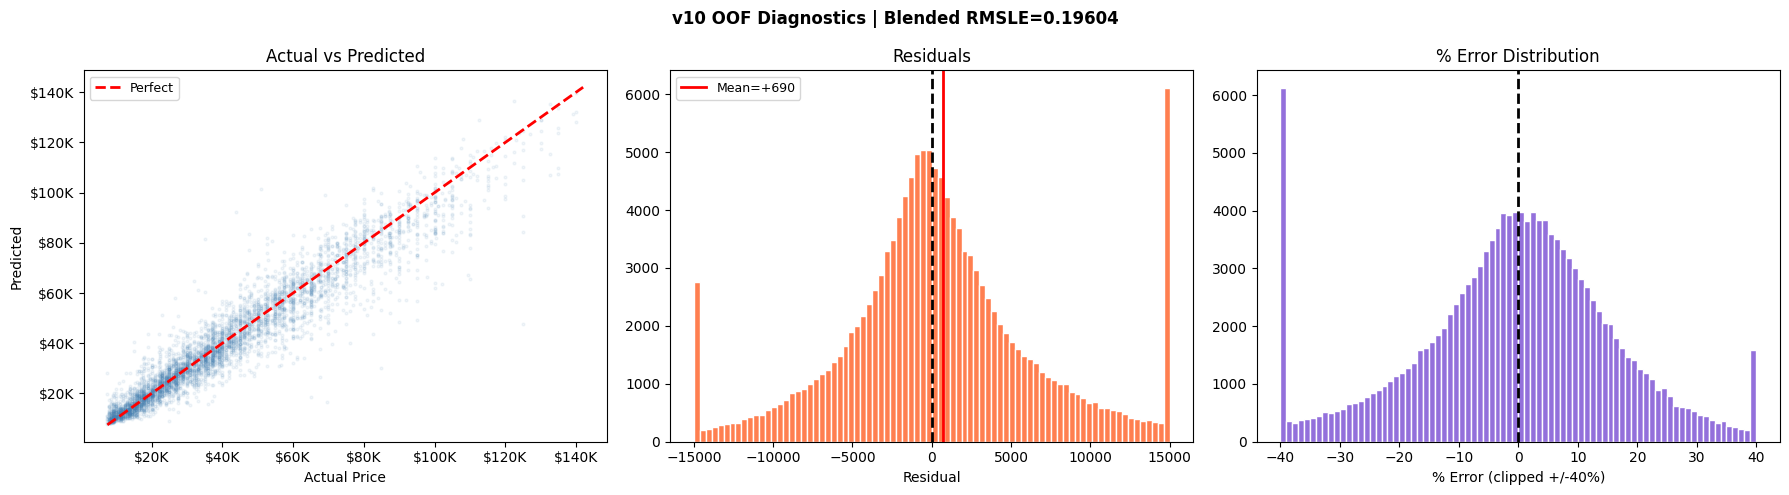

Blended OOF RMSLE : 0.19604
R^2               : 0.9130
MAE               : $5,141
Median % error    : 9.9%

Top 20 features (LGB fold 5):
SaleDayOfYear                  139783
SaleDay                        112800
AgeRelative                     95498
ManufactureYear                 87853
RegionCode                      82691
MachineAge                      78080
SaleYear                        74525
Spec_FullDescriptor_TE          72866
FunctionalClassification_TE     70279
Spec_BaseClass_TE               65284
ProductConfigID                 65011
UsagePerYear                    46098
OperationalHoursMeter           44464
Spec_BaseClass                  41772
SaleDayOfWeek                   41039
HoursRelative                   37228
SaleWeek                        34743
Spec_FullDescriptor             31888
ProductConfigID_TE              31700
FunctionalClassification        29064


In [12]:
oof_blend  = best_w[0]*oof_lgb + best_w[1]*oof_xgb + best_w[2]*oof_cat
pred_price = np.expm1(oof_blend)
true_price = np.expm1(y_all)
residuals  = true_price - pred_price
pct_err    = (residuals / true_price) * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(f'v10 OOF Diagnostics | Blended RMSLE={best_blend:.5f}',
             fontsize=12, fontweight='bold')

idx = np.random.choice(len(true_price), min(5000, len(true_price)), replace=False)
axes[0].scatter(true_price[idx], pred_price[idx], alpha=0.07, s=4, color='steelblue')
mn, mx = true_price.min(), true_price.max()
axes[0].plot([mn, mx], [mn, mx], 'r--', lw=2, label='Perfect')
axes[0].set_xlabel('Actual Price');  axes[0].set_ylabel('Predicted')
axes[0].set_title('Actual vs Predicted'); axes[0].legend(fontsize=9)
fmt = lambda x, _: f'${x/1000:.0f}K'
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(fmt))
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(fmt))

axes[1].hist(residuals.clip(-15000, 15000), bins=80, color='coral', edgecolor='white')
axes[1].axvline(0, color='black', lw=2, ls='--')
axes[1].axvline(residuals.mean(), color='red', lw=2, label=f'Mean={residuals.mean():+,.0f}')
axes[1].set_xlabel('Residual'); axes[1].set_title('Residuals'); axes[1].legend(fontsize=9)

axes[2].hist(pct_err.clip(-40, 40), bins=80, color='mediumpurple', edgecolor='white')
axes[2].axvline(0, color='black', lw=2, ls='--')
axes[2].set_xlabel('% Error (clipped +/-40%)'); axes[2].set_title('% Error Distribution')

plt.tight_layout(); plt.show()

print(f"Blended OOF RMSLE : {best_blend:.5f}")
print(f"R^2               : {r2_score(true_price, pred_price):.4f}")
print(f"MAE               : ${np.mean(np.abs(residuals)):,.0f}")
print(f"Median % error    : {np.median(np.abs(pct_err)):.1f}%")

# Feature importances (last LGB fold)
fi = pd.Series(lgb_m.feature_importances_,
               index=X_tr.columns).sort_values(ascending=False)
print("\nTop 20 features (LGB fold 5):")
print(fi.head(20).to_string())
